# Part B (01): Data preparation, v2 (group-aware split)
Steps: inspect, clean, select classes, **group-aware stratified split**, resize + normalize.


In [1]:
from pathlib import Path
import re, datetime, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split

SEED = 12
IMG_SIZE = (64, 64)
DATA_DIR = Path("../data")          
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

## Step 1: Inspect the raw data
The dataset already comes as train/valid/test folders with one folder per class.
We **pool everything** and re-split ourselves, as the guidelines require.

orig_split  test  train  valid   All
label                               
1             20     60     20   100
10            35    315     80   430
10 (new)      30    317    130   477
100           35    315     80   430
20            35    322     80   437
20 (new)      30    346    130   506
200           35    313     80   428
5             35    334     80   449
50            35    315     80   430
All          290   2637    760  3687


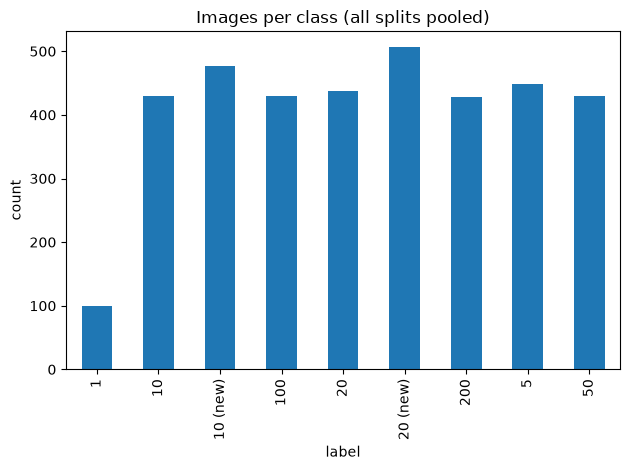

['IMG-20231217-WA0403.jpg', 'IMG_20231217_042224.jpg', 'photo_84_2023-12-16_04-05-38.jpg', 'IMG-20231217-WA0665.jpg', 'IMG_20231217_034817.jpg', 'photo_4_2023-12-16_04-05-38.jpg', 'IMG-20231217-WA0195.jpg', '34 - Copy.jpg']


In [2]:
files = [f for f in DATA_DIR.rglob("*") if f.is_file() and f.suffix.lower() in EXTS]
inv = pd.DataFrame({
    "path": files,
    "label": [f.parent.name for f in files],
    "orig_split": [f.parent.parent.name for f in files],
})
table = inv.pivot_table(index="label", columns="orig_split", values="path",
                        aggfunc="count", fill_value=0, margins=True)
print(table)

inv["label"].value_counts().sort_index().plot.bar(title="Images per class (all splits pooled)")
plt.ylabel("count"); plt.tight_layout(); plt.show()

print(inv["path"].map(lambda p: p.name).sample(8, random_state=SEED).tolist())

## Step 2: Quality checks
Corrupt files, exact duplicates (same bytes), and original sizes.

In [3]:
records = []
for _, r in inv.iterrows():
    f = r["path"]
    try:
        with Image.open(f) as im:
            im.verify()
        with Image.open(f) as im:
            w, h = im.size
            mode = im.mode
        records.append({"path": f, "label": r["label"], "orig_split": r["orig_split"],
                        "w": w, "h": h, "mode": mode,
                        "md5": hashlib.md5(f.read_bytes()).hexdigest()})
    except Exception as e:
        print("CORRUPT:", f, e)

df = pd.DataFrame(records)
print("valid images:", len(df))
print("exact duplicates:", df.duplicated("md5").sum())
print("modes:", df["mode"].value_counts().to_dict())
print(df[["w", "h"]].describe().loc[["min", "max", "mean"]])

valid images: 3687
exact duplicates: 452
modes: {'RGB': 3684, 'RGBA': 3}
                w            h
min    189.000000    86.000000
max   4160.000000  6000.000000
mean   908.759696   830.368321


In [4]:
df = df.drop_duplicates("md5").reset_index(drop=True)
print(df["label"].value_counts())

label
20 (new)    410
10 (new)    404
100         396
5           393
50          392
10          389
20          385
200         380
1            86
Name: count, dtype: int64


## Step 3: Select classes (3 to 5, >=100 images each, roughly balanced)

In [5]:
SELECTED = ["5", "10", "20", "50", "100"]
assert 3 <= len(SELECTED) <= 5, "choose 3 to 5 classes"
df = df[df["label"].isin(SELECTED)].reset_index(drop=True)
assert (df["label"].value_counts() >= 100).all(), "each class needs >= 100 images"
print(df["label"].value_counts())

label
100    396
5      393
50     392
10     389
20     385
Name: count, dtype: int64


## Step 4: Group-aware stratified split (about 70 / 15 / 15)
**Idea:** photos shot one after another show the same note in nearly the same scene. We build *groups* (sessions) and give every
group, as a whole, to train, validation or test. The split is still done **per class**, so each class keeps its proportions (stratified).

How a group is built (inside one class, in capture order):
- `IMG_YYYYMMDD_HHMMSS.jpg`: ordered by the time in the name; a new group starts after a gap of more than 60 seconds.
- `...WA0123.jpg` (WhatsApp): ordered by the number; a new group starts when the numbers jump by more than 2.
- `5.16.jpg` style: ordered by the second number; same rule as WhatsApp.
- Any other name: its own group.
- A group is cut at `MAX_GROUP` images so that very long sessions do not make the split unbalanced.

Whole groups are then shuffled (with `SEED`) and assigned to validation, then test, until each reaches about 15% of the class.

In [6]:
MAX_GROUP = 40
MAX_GAP = {"ts": 60.0, "wa": 2.0, "num": 2.0, "misc": 0.0}

def parse_name(name):
    m = re.match(r"IMG_(\d{8})_(\d{6})", name)
    if m:
        return "ts", datetime.datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S").timestamp()
    m = re.search(r"wa(\d+)", name.lower())
    if m:
        return "wa", float(m.group(1))
    m = re.match(r"\d+\.(\d+)", name)
    if m:
        return "num", float(m.group(1))
    return "misc", 0.0

def build_groups(frame):
    parsed = [parse_name(Path(p).name) for p in frame["path"]]
    d = pd.DataFrame({"label": frame["label"].values, "name": [Path(p).name for p in frame["path"]],
                      "kind": [k for k, _ in parsed], "key": [v for _, v in parsed]})
    d["row"] = np.arange(len(d))
    d = d.sort_values(["label", "kind", "key", "name"]).reset_index(drop=True)
    gid, g, size, prev = np.zeros(len(d), dtype=int), -1, 0, None
    for i, r in d.iterrows():
        new = (prev is None or r.label != prev.label or r.kind != prev.kind or r.kind == "misc"
               or (r.key - prev.key) > MAX_GAP[r.kind] or size >= MAX_GROUP)
        if new:
            g, size = g + 1, 0
        gid[i] = g; size += 1; prev = r
    d["group"] = gid
    d = d.sort_values("row")
    return d["group"].values, d["kind"].values, d["key"].values

def group_split(frame, seed, frac_val=0.15, frac_test=0.15, tol=8):
    groups, _, _ = build_groups(frame)
    labels = frame["label"].values
    rng = np.random.default_rng(seed)
    split = np.array(["train"] * len(frame), dtype=object)
    for c in sorted(set(labels)):
        members_by_group = {}
        for i in np.where(labels == c)[0]:
            members_by_group.setdefault(int(groups[i]), []).append(i)
        order = [members_by_group[k] for k in sorted(members_by_group)]
        n = sum(len(m) for m in order)
        target_val, target_test = round(frac_val * n), round(frac_test * n)
        n_val = n_test = 0
        for gi in rng.permutation(len(order)):
            m = order[gi]
            if n_val < target_val and n_val + len(m) <= target_val + tol:
                split[m] = "val"; n_val += len(m)
            elif n_test < target_test and n_test + len(m) <= target_test + tol:
                split[m] = "test"; n_test += len(m)
    return split, groups

In [7]:
df["split"], df["group"] = group_split(df, SEED)
df["kind"] = build_groups(df)[1]; df["key"] = build_groups(df)[2]

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df   = df[df["split"] == "val"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)

print("groups:", df["group"].nunique(), "| images per group (median):", int(df.groupby("group").size().median()))
print(pd.crosstab(df["label"], df["split"])[["train", "val", "test"]])
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(part), f"({len(part) / len(df):.1%})", part["label"].value_counts(normalize=True).round(3).to_dict())


assert (df.groupby("group")["split"].nunique() == 1).all()


df[["path", "label", "split", "group"]].to_csv("splits_part_b.csv", index=False)

groups: 74 | images per group (median): 37
split  train  val  test
label                  
10       280   49    60
100      280   61    55
20       260   65    60
5        270   64    59
50       272   60    60
train 1362 (69.7%) {'10': 0.206, '100': 0.206, '50': 0.2, '5': 0.198, '20': 0.191}
val 299 (15.3%) {'20': 0.217, '5': 0.214, '100': 0.204, '50': 0.201, '10': 0.164}
test 294 (15.0%) {'50': 0.204, '10': 0.204, '20': 0.204, '5': 0.201, '100': 0.187}


### Did it fix the leak?
For validation photos with a time in the file name: the share that has a **same-class train photo taken within 10 seconds**.
We compare with a plain stratified random split (what v1 did). Lower is better.

In [8]:
def leak_share(frame, split_col):
    t = frame[frame["kind"] == "ts"]
    tr, va = t[t[split_col] == "train"], t[t[split_col] == "val"]
    gaps = [np.abs(tr[tr["label"] == r.label]["key"].values - r.key).min() for r in va.itertuples()]
    return float(np.mean(np.array(gaps) <= 10)), len(va)

rnd_train, rnd_tmp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
rnd_val, rnd_test = train_test_split(rnd_tmp, test_size=0.50, stratify=rnd_tmp["label"], random_state=SEED)
df["random_split"] = "train"
df.loc[rnd_val.index, "random_split"] = "val"; df.loc[rnd_test.index, "random_split"] = "test"

print("random split :", leak_share(df, "random_split"))
print("group split  :", leak_share(df, "split"))

random split : (0.9157894736842105, 95)
group split  : (0.029556650246305417, 203)


## Step 5: Resize + normalize
`exif_transpose` fixes phone photos stored rotated. Pixels are scaled to [0, 1]. No statistics are learned here, so there is no leakage.

In [9]:


def load_images(frame):
    X = np.stack([
        np.asarray(ImageOps.exif_transpose(Image.open(p)).convert("RGB").resize(IMG_SIZE), dtype=np.float32) / 255.0
        for p in frame["path"]
    ])
    return X, frame["label"].to_numpy()

X_train_img, y_train = load_images(train_df)
X_val_img,   y_val   = load_images(val_df)
X_test_img,  y_test  = load_images(test_df)
print(X_train_img.shape, X_val_img.shape, X_test_img.shape)

(1362, 64, 64, 3) (299, 64, 64, 3) (294, 64, 64, 3)


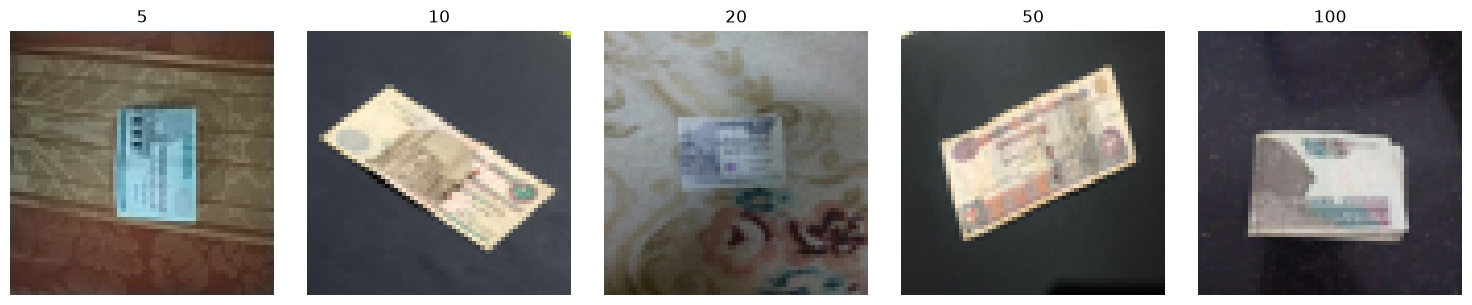

In [10]:
fig, axes = plt.subplots(1, len(SELECTED), figsize=(3 * len(SELECTED), 3))
for ax, cls in zip(np.atleast_1d(axes), SELECTED):
    idx = np.where(y_train == cls)[0][0]
    ax.imshow(X_train_img[idx]); ax.set_title(cls); ax.axis("off")
plt.tight_layout(); plt.show()